11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


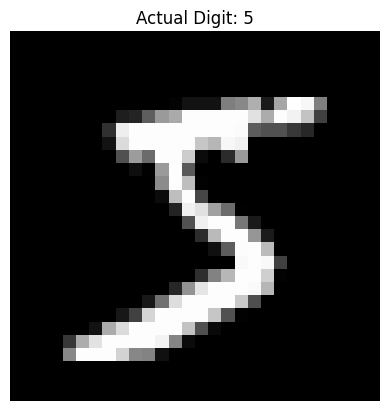

In [2]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
(x_train, y_train), (x_test, y_test) = (tf.keras.datasets.mnist.load_data())
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)
plt.imshow(x_train[0], cmap="gray")
plt.title(f"Actual Digit: {y_train[0]}")
plt.axis("off")
plt.show()

In [3]:

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())
print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Minimum pixel value: 0.0
Maximum pixel value: 1.0
Training shape: (60000, 28, 28)
Testing shape: (10000, 28, 28)


In [4]:

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9226 - loss: 0.2717 - val_accuracy: 0.9623 - val_loss: 0.1257
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9639 - loss: 0.1205 - val_accuracy: 0.9703 - val_loss: 0.1024
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9746 - loss: 0.0821 - val_accuracy: 0.9760 - val_loss: 0.0820
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9820 - loss: 0.0604 - val_accuracy: 0.9762 - val_loss: 0.0830
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9854 - loss: 0.0475 - val_accuracy: 0.9777 - val_loss: 0.0829


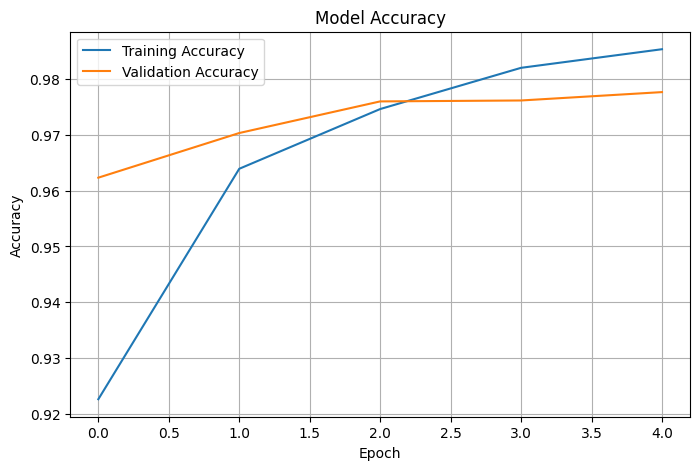

In [6]:

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

In [7]:

test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9747 - loss: 0.0832
Test Loss: 0.08315124362707138
Test Accuracy: 97.46999740600586 %


In [8]:

predictions = model.predict(x_test)
predicted_digits = np.argmax(predictions[:10], axis=1)
print("Actual digits:   ", y_test[:10])
print("Predicted digits:", predicted_digits)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Actual digits:    [7 2 1 0 4 1 4 9 5 9]
Predicted digits: [7 2 1 0 4 1 4 9 6 9]


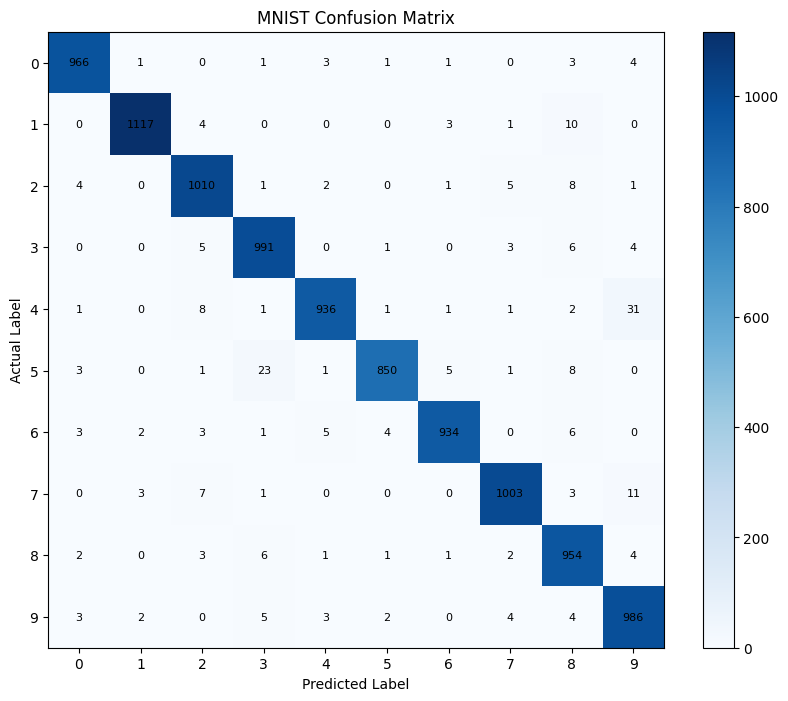

              precision    recall  f1-score   support

           0       0.98      0.99      0.98       980
           1       0.99      0.98      0.99      1135
           2       0.97      0.98      0.97      1032
           3       0.96      0.98      0.97      1010
           4       0.98      0.95      0.97       982
           5       0.99      0.95      0.97       892
           6       0.99      0.97      0.98       958
           7       0.98      0.98      0.98      1028
           8       0.95      0.98      0.96       974
           9       0.95      0.98      0.96      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.98      0.97      0.97     10000



In [9]:

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
y_pred = np.argmax(predictions, axis=1)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
plt.imshow(cm, cmap="Blues")
plt.title("MNIST Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.colorbar()
plt.xticks(range(10))
plt.yticks(range(10))
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j],
                 ha="center", va="center",
                 color="black", fontsize=8)
plt.show()
print(classification_report(y_test, y_pred))


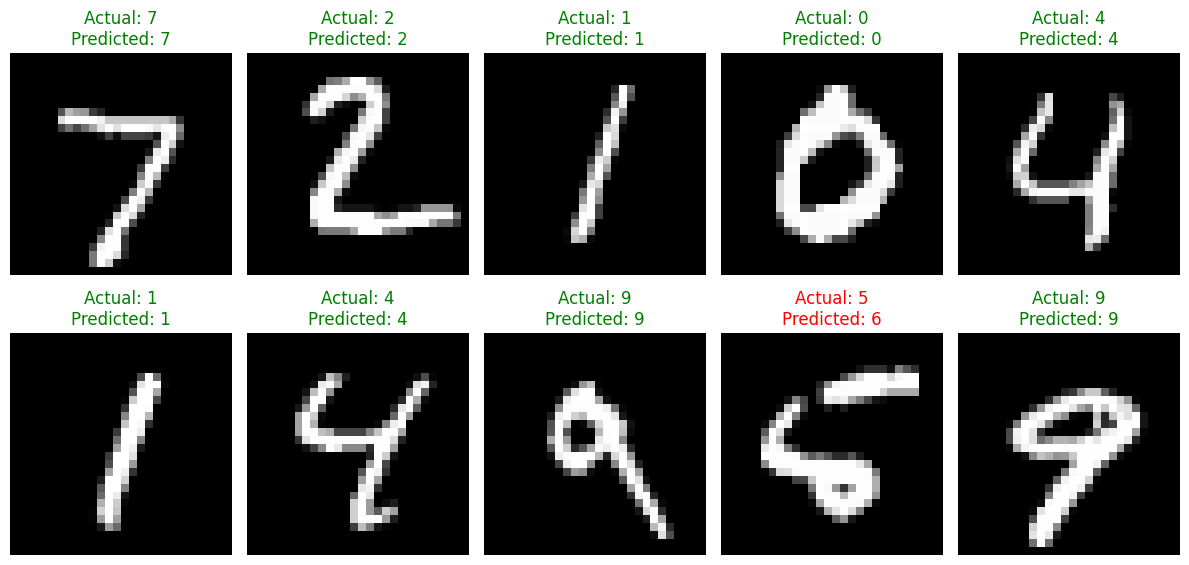

In [10]:

plt.figure(figsize=(12, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    actual = y_test[i]
    predicted = y_pred[i]
    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color="green" if actual == predicted else "red"
    )
    plt.axis("off")
plt.tight_layout()
plt.show()

In [11]:
!pip install gradio

In [14]:

def predict_digit(image):
    import numpy as np
    from PIL import Image
    if isinstance(image, dict):
        image = image.get("composite", None)
    if image is None:
        return {"No image": 1.0}
    image = Image.fromarray(
        np.uint8(image)
    ).convert("L")
    image = image.resize((28, 28))
    image = np.array(image)
    image = 255 - image
    image = image.astype("float32") / 255.0
    image = image.reshape(1, 28, 28)
    prediction = model.predict(image, verbose=0)
    return {
        str(i): float(prediction[0][i])
        for i in range(10)
    }

In [15]:

demo = gr.Interface(
    fn=predict_digit,
    inputs=gr.Sketchpad(
        type="numpy",
        image_mode="RGB",
        label="Draw a digit from 0 to 9"
    ),
    outputs=gr.Label(
        num_top_classes=3,
        label="Digit Prediction"
    ),
    title="MNIST Digit Recognition",
    description="Draw a digit from 0 to 9."
)
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://cdd35233025b0c2ec9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
